# The smell pathway: ORNs to Kenyon cells to MBONs

The olfactory pathway of the fly runs from the olfactory receptor neurons (`ORN_*`, 53 glomerular
types, one per antennal-lobe glomerulus) through the uniglomerular projection neurons
(`<glomerulus>_lPN`/`_adPN`/`_vPN`) to the Kenyon cells (`KC*`, the mushroom body's ~4,000-neuron
expansion layer) and on to the mushroom-body output neurons (`MBON*`, 36 types). In a real fly,
Kenyon-cell activity is famously **sparse**: in vivo, a single odor activates roughly **5-10% of
the Kenyon population** (Honegger, Campbell & Turner 2011, *Cell*; Turner, Bazhenov & Loesel 2008,
*J. Neurophysiol*).

This notebook builds odors as sets of ORN types, drives them at several strengths, and measures
what happens at each stage of that pathway in the model.

The answer is a **negative result**, and a clear one. It comes in three parts:

1. **The first relay works.** Injecting an ORN type drives its glomerular projection neurons hard
   (from their ~16 Hz rest rate to near the model's 50 Hz ceiling).
2. **The Kenyon-cell layer is saturated at rest.** In the model's calibrated configuration, about
   **4,063 of 4,064 Kenyon cells fire on every single step** with no odor at all. The repository's
   own `notebooks/reservoir.ipynb` records the same thing ("Kenyon cells active at a given step:
   100.0%" for the connectome), and gets chance-level (9.2%) digit readouts from Kenyon cells.
3. **So the smell signal vanishes at the Kenyon stage.** In seven of eight noise seeds, odor
   stimulation changes Kenyon-cell spiking by at most ~24 extra spikes across the whole
   population in a 1 s window (well under 0.1% of the Kenyon spike-slots), regardless of
   strength; the overlap between any two odors' Kenyon "patterns" is a Jaccard of ~1.0; and MBONs barely
   respond (a few spikes per second at best, on a ~91%-saturated baseline). (The eighth seed sits on a tipping point -- see below.) The same
   measurement on a degree-preserving rewiring of the same model, whose Kenyon layer is *not*
   saturated, sees the same odor move ~25% of the Kenyon population (against well under 0.1%
   on the connectome) -- so the flat connectome result is the wiring's, not the measurement's.

The model therefore does **not** reproduce the 5-10% sparse Kenyon code. We do not retune any
parameter to make it appear (the issue forbids tuning to hit the number); we show instead how the
result depends on input strength (it does not, up to 4.0 V/step), and that the saturation is a
property of the real wiring: on a degree-preserving rewiring of the same model, resting Kenyon
activity drops to ~5% in this notebook's measurement window (the repository's reservoir notebook
reports 18-27% for random wirings under its own, different window).

**Before running:** `pip install flybrain matplotlib scipy`. The first `FlyBrain()` downloads the
brain (~260 MB) once. Everything runs on the CPU; the whole notebook takes about **2-4 minutes**
(three executions on the same 12-thread machine: 1 min 34 s, 2 min 11 s and 3 min 52 s,
machine load varying; identical numbers every time).
Plots and the number tables are saved next to this notebook, in `notebooks/smell/`
(`pn_response.png`, `kc_extras.png`, `saturation_control.png`, `pn_response.csv`,
`kc_extras.csv`), whether it is run from `notebooks/` or from the repository root.

**No claims about learning:** flybrain has no plasticity in the mushroom body; nothing here says
anything about odor learning, only about the feedforward sweep ORN -> PN -> KC -> MBON.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import platform

import flybrain
from flybrain import FlyBrain

# outputs go next to this notebook, whether it is run from notebooks/ or from the repo root
HERE = next(p for p in (Path.cwd(), Path.cwd() / "notebooks") if (p / "smell.ipynb").exists())
OUT = HERE / "smell"
OUT.mkdir(exist_ok=True)

# sensory_input=False removes every synapse ONTO sensory neurons. With the default True,
# ORN-to-ORN synapses pin the olfactory receptor neurons near their maximum rate at rest,
# so odours add nothing (see FlyBrain's docstring and README finding 4). The repository's
# olfactory work (notebooks/reservoir.ipynb) uses the same setting.
brain = FlyBrain(device="cpu", sensory_input=False)
ct = brain.cell_type.astype(str)

orn_types = sorted(np.unique(ct[np.char.startswith(ct, "ORN_")]))
kc = np.flatnonzero(np.char.startswith(ct, "KC"))
mbons = np.flatnonzero(np.char.startswith(ct, "MBON"))
print(f"flybrain {flybrain.__version__} on {platform.system()} ({platform.machine()}): "
      f"{brain.n:,} neurons; {len(orn_types)} ORN types, {len(kc)} Kenyon cells, "
      f"{len(np.unique(ct[mbons]))} MBON types ({len(mbons)} neurons)")

flybrain 0.1.1 on Darwin (arm64): 166,700 neurons; 53 ORN types, 4064 Kenyon cells, 36 MBON types (97 neurons)


## Odors

Three single glomeruli (`ORN_DM1`, `ORN_DL5`, `ORN_VA2`, each tens of receptor neurons on both
sides) and two seeded random mixtures (4 and 10 glomeruli). A 2 s trial (100 steps of 20 ms) with
the odor on for the middle 1 s; the injected voltage is added to every ORN of the chosen types at
every step while on. Seven strengths: 0.1, 0.3, 0.5, 0.7, 1.0, 2.0, 4.0 V per step (fine steps
across the range where the projection-neuron response rises). Eight noise seeds per
condition, and a matched-noise blank run per seed (same noise, no odor) so every "extra" below is
odor minus blank, not odor minus nothing.

For each odor we also name its **projection neurons** (`<glomerulus>_lPN` / `_adPN` / `_vPN`) --
the uniglomerular cells that in a real fly copy one glomerulus' ORN input to the mushroom body and
lateral horn.

In [2]:
rng = np.random.default_rng(7)
others = [t for t in orn_types if t not in ("ORN_DM1", "ORN_DL5", "ORN_VA2")]
mix4 = [others[i] for i in rng.permutation(len(others))[:4]]
mix10 = [others[i] for i in rng.permutation(len(others))[:10]]
ODORS = {"DM1": ["ORN_DM1"], "DL5": ["ORN_DL5"], "VA2": ["ORN_VA2"], "mix4": mix4, "mix10": mix10}
STRENGTHS = [0.1, 0.3, 0.5, 0.7, 1.0, 2.0, 4.0]   # fine steps across the PN rise (0.5-1.0)
SEEDS = list(range(8))
T, ON, TAIL = 100, (25, 75), 5          # odor on for 1 s; +5 steps of tail for propagation


def pns_for(types):
    '''Uniglomerular projection neurons of a mixture's glomeruli.'''
    names = [t.removeprefix("ORN_") for t in types]
    return brain.cells([f"{g}_{s}" for g in names for s in ("lPN", "adPN", "vPN")])


def slot_of(idx):
    s = np.full(brain.n, -1, np.int64)
    s[idx] = np.arange(len(idx))
    return s


kc_slot, mbon_slot = slot_of(kc), slot_of(mbons)
mbon_ct = ct[mbons]

for name, types in ODORS.items():
    idx, pn = brain.cells(types), pns_for(types)
    print(f"{name:6s}: {len(types):2d} ORN types ({len(idx):3d} neurons) -> {len(pn):2d} uniglomerular PNs")


def trial(seed, idx, amount, pn_idx=None):
    '''One 2 s run. Per-step firing fractions over the window + tail for the
    injected ORNs, their PNs and the Kenyon cells; spike counts for all neurons.'''
    brain.reset(seed)
    pn_idx = np.asarray(pn_idx if pn_idx is not None else [])
    orn_slot = slot_of(idx) if len(idx) else None
    pn_slot = slot_of(pn_idx) if len(pn_idx) else None
    out = {k: np.zeros(ON[1] - ON[0] + TAIL) for k in ("orn", "pn", "kc")}
    kc_counts = np.zeros(brain.n, np.int32)
    mbon_counts = np.zeros(brain.n, np.int32)
    i = 0
    for t in range(T):
        fired = brain.step(inject=[(idx, amount)] if ON[0] <= t < ON[1] else ())
        if ON[0] <= t < ON[1] + TAIL:
            if len(fired):
                if orn_slot is not None:
                    h = orn_slot[fired]; out["orn"][i] = (h >= 0).sum() / len(idx)
                if pn_slot is not None:
                    h = pn_slot[fired]; out["pn"][i] = (h >= 0).sum() / max(1, len(pn_idx))
                h = kc_slot[fired]; out["kc"][i] = (h >= 0).sum() / len(kc)
                kc_counts[fired] += 1
                mbon_counts[fired] += 1
            i += 1
    return out, kc_counts, mbon_counts

DM1   :  1 ORN types ( 74 neurons) ->  2 uniglomerular PNs
DL5   :  1 ORN types ( 43 neurons) ->  2 uniglomerular PNs
VA2   :  1 ORN types ( 83 neurons) ->  2 uniglomerular PNs
mix4  :  4 ORN types (252 neurons) -> 16 uniglomerular PNs
mix10 : 10 ORN types (436 neurons) -> 43 uniglomerular PNs


## First, the resting state

Before any odor: how active is each stage? (This is the fact the whole result turns on, so we
measure it first.)

In [3]:
rest = {}
for seed in SEEDS:
    rest[seed] = trial(seed, np.empty(0, np.int64), 0.0)
kc_frac = np.array([rest[s][0]["kc"] for s in SEEDS])
for seed in SEEDS:
    print(f"  seed {seed}: Kenyon cells firing per step at rest {100 * kc_frac[SEEDS.index(seed)].mean():.2f}%")
print(f"median seed: {100 * np.median(kc_frac):.2f}% of {len(kc)} Kenyon cells fire every step")
spikes = [len(brain.step()) for _ in range(20)]
print(f"whole-brain spikes per step at rest: ~{np.mean(spikes):.0f}")

  seed 0: Kenyon cells firing per step at rest 99.97%
  seed 1: Kenyon cells firing per step at rest 99.97%
  seed 2: Kenyon cells firing per step at rest 99.97%
  seed 3: Kenyon cells firing per step at rest 99.97%
  seed 4: Kenyon cells firing per step at rest 93.02%
  seed 5: Kenyon cells firing per step at rest 99.97%
  seed 6: Kenyon cells firing per step at rest 99.97%
  seed 7: Kenyon cells firing per step at rest 99.60%
median seed: 99.98% of 4064 Kenyon cells fire every step
whole-brain spikes per step at rest: ~7605


## Run the odor sweep

In [4]:
t0 = time.time()
res, blank, pn_of = {}, {}, {}
for name, types in ODORS.items():
    idx = brain.cells(types)
    pn_of[name] = pns_for(types)
    for a in STRENGTHS:
        for seed in SEEDS:
            res[name, a, seed] = trial(seed, idx, a, pn_of[name])
for seed in SEEDS:
    blank[seed] = trial(seed, np.empty(0, np.int64), 0.0, pn_of["DM1"])   # blank also watches DM1's PNs
print(f"{len(res) + len(blank)} runs in {(time.time() - t0) / 60:.1f} min")

288 runs in 1.3 min


## The first relay works: projection neurons

Injected ORNs follow the drive, and their uniglomerular projection neurons follow them: from a
~0.3 per-step rest rate (about 16 Hz, matching the README's measured DM1/DM2 rest rate) up to
the one-spike-per-step ceiling (~50 Hz) from 1.0 V on. The mid range is not monotonic -- the
PN rate steps through ~0.43, ~0.56, ~0.48, ~0.53 as the drive rises (regime changes in how
often the ORNs fire, not a smooth curve) -- so the sweep samples it finely. Whatever the exact
shape, the signal crosses ORN -> PN strongly, on the odor's own glomeruli.

In [5]:
import csv

pn_rows = []
print(f"{'odor':6s} {'V/step':>6s} {'ORN fired/step':>15s} {'PN fired/step':>17s}")
for name in ODORS:
    for a in STRENGTHS:
        orn = np.array([res[name, a, s][0]["orn"].mean() for s in SEEDS])
        pn = np.array([res[name, a, s][0]["pn"].mean() for s in SEEDS])
        print(f"{name:6s} {a:6.1f} {orn.mean():9.2f}±{orn.std(ddof=1):5.2f} "
              f"{pn.mean():11.2f}±{pn.std(ddof=1):5.2f}")
        pn_rows.append((name, a, orn.mean(), orn.std(ddof=1), pn.mean(), pn.std(ddof=1)))
pn_blank = np.mean([blank[s][0]["pn"].mean() for s in SEEDS])
print(f"{'blank':6s} {0.0:6.1f} {'--':>15s} {pn_blank:11.2f}       (DM1's PNs, same seeds, no odor)")
with open(OUT / "pn_response.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["odor", "v_per_step", "orn_per_step_mean", "orn_per_step_sd",
                "pn_per_step_mean", "pn_per_step_sd"])
    w.writerows([(n, a, round(o, 4), round(os_, 4), round(p, 4), round(ps, 4))
                 for n, a, o, os_, p, ps in pn_rows])
print("saved", OUT / "pn_response.csv")

odor   V/step  ORN fired/step     PN fired/step
DM1       0.1      0.12± 0.00        0.43± 0.01
DM1       0.3      0.31± 0.00        0.56± 0.03
DM1       0.5      0.45± 0.00        0.48± 0.00
DM1       0.7      0.46± 0.00        0.53± 0.04
DM1       1.0      0.91± 0.00        0.93± 0.00
DM1       2.0      0.91± 0.00        0.93± 0.00
DM1       4.0      0.91± 0.00        0.93± 0.00
DL5       0.1      0.12± 0.00        0.44± 0.02
DL5       0.3      0.31± 0.00        0.56± 0.04
DL5       0.5      0.45± 0.00        0.48± 0.01
DL5       0.7      0.46± 0.00        0.55± 0.06
DL5       1.0      0.91± 0.00        0.93± 0.01
DL5       2.0      0.91± 0.00        0.93± 0.01
DL5       4.0      0.91± 0.00        0.93± 0.01
VA2       0.1      0.12± 0.00        0.37± 0.02
VA2       0.3      0.31± 0.00        0.47± 0.05
VA2       0.5      0.45± 0.00        0.48± 0.00
VA2       0.7      0.46± 0.00        0.50± 0.02
VA2       1.0      0.91± 0.00        0.93± 0.01
VA2       2.0      0.91± 0.00        0.9

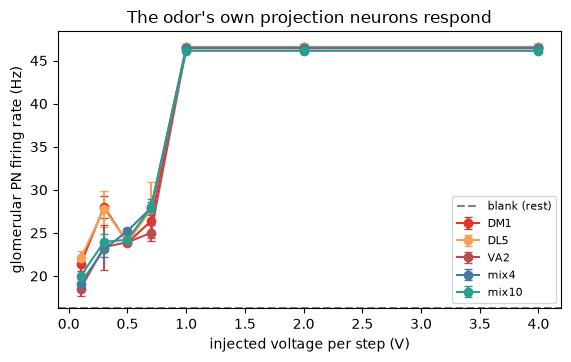

saved /private/tmp/nb49/run4/smell/pn_response.png


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, color in zip(ODORS, ("#e0342c", "#f4a259", "#bc4b51", "#457b9d", "#2a9d8f")):
    pn = [np.mean([res[name, a, s][0]["pn"].mean() for s in SEEDS]) * 50 for a in STRENGTHS]
    sd = [np.std([res[name, a, s][0]["pn"].mean() for s in SEEDS], ddof=1) * 50 for a in STRENGTHS]
    ax.errorbar(STRENGTHS, pn, yerr=sd, marker="o", capsize=3, color=color, label=name)
ax.axhline(pn_blank * 50, ls="--", c="0.5", label="blank (rest)")
ax.set_xlabel("injected voltage per step (V)")
ax.set_ylabel("glomerular PN firing rate (Hz)")
ax.set_title("The odor's own projection neurons respond")
ax.legend(fontsize=8)
plt.savefig(OUT / "pn_response.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", OUT / "pn_response.png")

## The Kenyon layer: saturated, so the odor adds nothing

Now the measurement the issue asks for: **the fraction of Kenyon cells that spike**. Over a whole
1 s window the answer is ~100% for every odor, every strength, every seed -- but it is also ~100%
for the blank. Kenyon cells at rest fire every step in this configuration, so "fraction that
spikes" cannot separate an odor from no odor. The informative number is the **odor-attributable**
spiking: Kenyon spikes in the stimulus run minus the matched-noise blank run, per seed.

For **seven of the eight seeds that number is effectively zero at every strength**: per-seed
extras of -12 to +24 spikes (medians -4 to +17) in a window that contains ~220,000 Kenyon
spike-slots (4,064 neurons x 55 steps) -- well under 0.1% of Kenyon cells gain even one spike.
**One seed sits on a tipping point instead**: in that noise trajectory the blank run's Kenyon
layer settles at ~93% per step rather than ~100%, and the odor tips it over (the cell below
identifies the seed and measures exactly what tips). The layer is metastable between
nearly-saturated regimes, not stably sparse. In the in-vivo literature, 5-10% of Kenyon cells
*respond* to an odor; here the typical seed shows **at most a few hundredths of a percent
gaining a spike**, and the population is ~100% active before the odor arrives.

In [7]:
print(f"{'odor':6s} {'V/step':>6s} {'extra KC spikes, per seed':>34s} {'median':>7s} {'max':>6s}")
kc_rows = []
for name in ODORS:
    for a in STRENGTHS:
        extra = np.stack([res[name, a, s][1][kc] - blank[s][1][kc] for s in SEEDS])
        tot = extra.sum(1)
        print(f"{name:6s} {a:6.1f} {str(tot.tolist()):>34s} {np.median(tot):7.0f} {tot.max():6.0f}")
        kc_rows.append([name, a] + tot.tolist() + [float(np.median(tot)), float(tot.max())])
with open(OUT / "kc_extras.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["odor", "v_per_step"] + [f"seed{s}" for s in SEEDS] + ["median", "max"])
    w.writerows(kc_rows)
print("saved", OUT / "kc_extras.csv")

odor   V/step          extra KC spikes, per seed  median    max
DM1       0.1     [5, -2, 3, 13, 376, 6, -4, -1]       4    376
DM1       0.3       [3, 2, 5, 15, 772, 13, 0, 5]       5    772
DM1       0.5         [4, 1, 4, 3, 918, 4, 1, 7]       4    918
DM1       0.7        [5, 2, 5, 7, 920, 12, 2, 4]       5    920
DM1       1.0 [11, 13, 14, 20, 1555, 21, 15, 12]      14   1555
DM1       2.0 [11, 13, 14, 20, 1555, 21, 15, 12]      14   1555
DM1       4.0 [11, 13, 14, 20, 1555, 21, 15, 12]      14   1555
DL5       0.1    [-3, -3, -7, 4, 133, -1, 1, -2]      -2    133
DL5       0.3    [2, -9, -4, -3, 337, 5, -6, -4]      -4    337
DL5       0.5     [-3, -3, -1, 4, 550, 4, 2, -7]       0    550
DL5       0.7      [5, -3, 2, 4, 547, 4, -1, -4]       3    547
DL5       1.0  [-1, -2, 10, 13, 792, -1, -2, -2]      -1    792
DL5       2.0  [-1, -2, 10, 13, 792, -1, -2, -2]      -1    792
DL5       4.0  [-1, -2, 10, 13, 792, -1, -2, -2]      -1    792
VA2       0.1      [2, -11, 1, 6, 304, 9

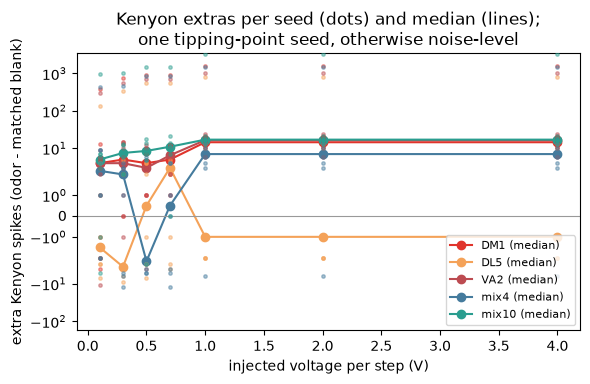

saved /private/tmp/nb49/run4/smell/kc_extras.png


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, color in zip(ODORS, ("#e0342c", "#f4a259", "#bc4b51", "#457b9d", "#2a9d8f")):
    tot = np.stack([np.stack([res[name, a, s][1][kc] - blank[s][1][kc] for s in SEEDS]).sum(1)
                    for a in STRENGTHS])          # (strength, seed)
    ax.plot(STRENGTHS, np.median(tot, 1), marker="o", color=color, label=f"{name} (median)")
    ax.scatter(np.repeat(STRENGTHS, len(SEEDS)), tot.ravel(), s=6, color=color, alpha=0.45,
               zorder=3)
ax.axhline(0, c="0.6", lw=0.8)
ax.set_yscale("symlog")
ax.set_xlabel("injected voltage per step (V)")
ax.set_ylabel("extra Kenyon spikes (odor - matched blank)")
ax.set_title("Kenyon extras per seed (dots) and median (lines);\none tipping-point seed, otherwise noise-level")
ax.legend(fontsize=8)
plt.savefig(OUT / "kc_extras.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", OUT / "kc_extras.png")

### Overlap between odors

Two different odors should activate different Kenyon subsets; in vivo their patterns overlap only
weakly. Here the "pattern" of every odor is the same ~all-Kenyon set the blank produces, so the
Jaccard overlap of any two odors' Kenyon spike sets is ~1.0 -- the set contains no odor
information at all.

In [9]:
names = list(ODORS)
print(f"Jaccard overlap of Kenyon spike sets at 1.0 V (mean over {len(SEEDS)} seeds):")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        ov = []
        for s in SEEDS:
            a = res[names[i], 1.0, s][1][kc] > 0
            b = res[names[j], 1.0, s][1][kc] > 0
            union = (a | b).sum()
            ov.append((a & b).sum() / union if union else np.nan)
        print(f"  {names[i]:6s} vs {names[j]:6s}: {np.mean(ov):.3f}")

Jaccard overlap of Kenyon spike sets at 1.0 V (mean over 8 seeds):
  DM1    vs DL5   : 1.000
  DM1    vs VA2   : 1.000
  DM1    vs mix4  : 1.000
  DM1    vs mix10 : 1.000
  DL5    vs VA2   : 1.000
  DL5    vs mix4  : 1.000
  DL5    vs mix10 : 1.000
  VA2    vs mix4  : 1.000
  VA2    vs mix10 : 1.000
  mix4   vs mix10 : 1.000


### The tipping-point seed, isolated

The `max` column above is one seed, not a typical response. Here it is, measured directly.

In [10]:
best = max(((name, a, seed, res[name, a, seed][1][kc] - blank[seed][1][kc])
             for name in ODORS for a in STRENGTHS for seed in SEEDS),
            key=lambda r: r[3].sum())
name, a, seed, extra = best
frac_blank = rest[seed][0]["kc"].mean()
frac_stim = res[name, a, seed][0]["kc"].mean()
print(f"largest odor effect in the whole sweep: odor {name} at {a:.1f} V/step, seed {seed}")
print(f"  that seed's blank run:   {100 * frac_blank:.2f}% of Kenyon cells fire per step")
print(f"  that seed's odor run:    {100 * frac_stim:.2f}% of Kenyon cells fire per step")
print(f"  extra spikes (odor - blank): {int(extra.sum())} across the 1 s window")
print(f"  Kenyon cells gaining >= 1 spike: {(extra > 0).sum()} of {len(kc)} "
      f"({100 * (extra > 0).mean():.1f}%)")
print(f"  all other seeds, same condition: "
      f"{[int((res[name, a, s][1][kc] - blank[s][1][kc]).sum()) for s in SEEDS if s != seed]}")

largest odor effect in the whole sweep: odor mix10 at 1.0 V/step, seed 4
  that seed's blank run:   93.02% of Kenyon cells fire per step
  that seed's odor run:    94.49% of Kenyon cells fire per step
  extra spikes (odor - blank): 3277 across the 1 s window
  Kenyon cells gaining >= 1 spike: 1957 of 4064 (48.2%)
  all other seeds, same condition: [17, 16, 13, 18, 21, 17, 17]


## MBONs: a saturated readout barely moves

Mushroom-body output neurons receive the Kenyon cells -- and at rest they are **also nearly
saturated** (about 91% of MBON spike-slots are used before any odor). On a baseline already at
the ceiling, an odor can only nudge: across seeds the best MBON neurons gain a few spikes per
second at most (per-seed extras of -1 to +5 spikes over the 1 s window; median +2.5 for the
strongest, positive in 7 of 8 seeds). A real fly's MBONs respond to an odor in tens of spikes
per second, from a quiet baseline; here the response is marginal and the dynamic range for
distinguishing odors is a couple of spikes.

In [11]:
blank_mbon = np.stack([blank[s][2][mbons] for s in SEEDS])
print(f"MBON spikes at rest: {blank_mbon.sum(1).mean():.0f} over the window across {len(mbons)} "
      f"neurons = {100 * blank_mbon.sum(1).mean() / (len(mbons) * 55):.0f}% of MBON spike-slots")
print("Top-3 MBON neurons per odor at 1.0 V (extra spikes over the 1 s window, median / max;")
print("several neurons can share one MBON type):")
for name in ODORS:
    extra = np.stack([res[name, 1.0, s][2][mbons] - blank[s][2][mbons] for s in SEEDS])
    top = np.argsort(-np.median(extra, 0))[:3]
    print(f"  {name:6s}: " + "; ".join(
        f"{mbon_ct[i]:>8s}[{i:>2d}] {np.median(extra[:, i]):+.1f}/{extra[:, i].max():+.1f} "
        f"({(extra[:, i] > 0).sum()}/{len(SEEDS)} seeds +)" for i in top))

MBON spikes at rest: 4853 over the window across 97 neurons = 91% of MBON spike-slots
Top-3 MBON neurons per odor at 1.0 V (extra spikes over the 1 s window, median / max;
several neurons can share one MBON type):
  DM1   :   MBON10[48] +2.0/+3.0 (7/8 seeds +);   MBON10[92] +1.0/+2.0 (6/8 seeds +);   MBON20[ 9] +1.0/+4.0 (5/8 seeds +)
  DL5   :   MBON10[55] +0.5/+4.0 (4/8 seeds +);   MBON01[ 0] +0.0/+0.0 (0/8 seeds +);   MBON27[70] +0.0/+1.0 (1/8 seeds +)
  VA2   :   MBON10[48] +2.5/+5.0 (7/8 seeds +);   MBON10[92] +1.0/+2.0 (7/8 seeds +);   MBON10[55] +1.0/+3.0 (4/8 seeds +)
  mix4  :   MBON20[ 9] +1.0/+2.0 (6/8 seeds +);   MBON10[48] +0.5/+2.0 (4/8 seeds +);   MBON10[92] +0.5/+2.0 (4/8 seeds +)
  mix10 :   MBON10[48] +1.0/+4.0 (6/8 seeds +);   MBON10[92] +1.0/+2.0 (6/8 seeds +);   MBON10[55] +1.0/+2.0 (5/8 seeds +)


## Is the saturation the wiring's fault?

The Kenyon cells being pinned at the ceiling is a property of the **real connectome's** recurrent
drive in this model recipe, not of the recipe alone: the repository's `notebooks/reservoir.ipynb`
records Kenyon activity of 100% for the connectome but only 18-27% for random rewirings of the
same model. We reproduce that control here, over all eight seeds (degree-preserving rewiring: every neuron keeps its
in- and out-degree and its synaptic signs; who connects to whom is random, and incoming weight
strengths are rescaled to match) -- resting Kenyon activity collapses when the wiring is
scrambled. Whatever the mechanism, it lives in the real wiring. (This control measures a
30-step window after a 25-step settle, shorter than the sweep's 55-step window, so the
metastable seed 4 reads 87.2% here against 93.02% above -- same seed, different window, and
the point is unchanged.)

(Swapping the weight matrix uses `FlyBrain`'s internal arrays, exactly as `reservoir.ipynb` does;
it is a notebook trick, not a public API.)

resting Kenyon cells firing per step, per seed:
  connectome: ['100.0', '100.0', '100.0', '100.0', '87.2', '100.0', '100.0', '99.3']
  rewired:    ['4.9', '5.0', '5.1', '4.9', '5.0', '5.2', '5.0', '5.0']
means: connectome 98.3% ± 4.5, degree-preserving rewiring 5.0% ± 0.1


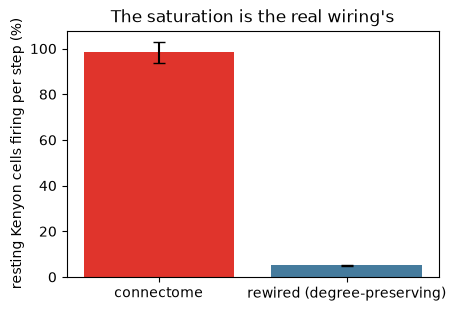

saved /private/tmp/nb49/run4/smell/saturation_control.png


In [12]:
from scipy import sparse

original = sparse.csc_matrix((brain.weights, brain.indices, brain.indptr), shape=(brain.n, brain.n)).tocsr()
row_strength = np.asarray(abs(original).sum(1)).ravel()


def match_input_strength(W):
    W = W.tocsr()
    W.sum_duplicates()
    s = np.asarray(abs(W).sum(1)).ravel()
    scale = np.divide(row_strength, s, out=np.zeros_like(s), where=s > 0)
    W = sparse.diags(scale.astype(np.float32)) @ W
    W.eliminate_zeros()
    return W.tocsr()


coo = original.tocoo()
post = np.random.default_rng(11).permutation(coo.row)
shuffled = match_input_strength(sparse.coo_matrix((coo.data, (post, coo.col)), shape=original.shape))


def use_weights(W):
    W = W.tocsr().astype(np.float32)
    W.sort_indices()
    csc = W.tocsc()
    brain.indptr, brain.indices, brain.weights = csc.indptr, csc.indices, csc.data


def rest_kc_fraction(seeds, settle=25, steps=30):
    '''The same window the sweep uses: settle for 25 steps, then measure.'''
    fr = []
    for seed in seeds:
        brain.reset(seed)
        for _ in range(settle):
            brain.step()
        c = 0
        for _ in range(steps):
            fired = brain.step()
            c += (kc_slot[fired] >= 0).sum() if len(fired) else 0
        fr.append(c / (steps * len(kc)))
    return np.array(fr)


frac_real = rest_kc_fraction(SEEDS)
use_weights(shuffled)
frac_shuffled = rest_kc_fraction(SEEDS)
use_weights(original)
print("resting Kenyon cells firing per step, per seed:")
print("  connectome:", [f"{100 * v:.1f}" for v in frac_real])
print("  rewired:   ", [f"{100 * v:.1f}" for v in frac_shuffled])
print(f"means: connectome {100 * frac_real.mean():.1f}% ± {100 * frac_real.std(ddof=1):.1f}, "
      f"degree-preserving rewiring {100 * frac_shuffled.mean():.1f}% "
      f"± {100 * frac_shuffled.std(ddof=1):.1f}")

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.bar([0, 1], [100 * frac_real.mean(), 100 * frac_shuffled.mean()],
       yerr=[100 * frac_real.std(ddof=1), 100 * frac_shuffled.std(ddof=1)], capsize=4,
       color=["#e0342c", "#457b9d"])
ax.set_xticks([0, 1], ["connectome", "rewired (degree-preserving)"])
ax.set_ylabel("resting Kenyon cells firing per step (%)")
ax.set_title("The saturation is the real wiring's")
plt.savefig(OUT / "saturation_control.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", OUT / "saturation_control.png")

## The same odor on the rewired brain

The connectome's Kenyon layer is saturated, so the odor has nothing to move there. On the
degree-preserving rewiring the layer is *not* saturated (~5% at rest) -- if the odor reaches
Kenyon cells at all, it should be visible there. This is the control that shows the flat
connectome result is the wiring's, not a blind spot of the measurement: the same odor, the
same injection, the same matched-noise subtraction, on the rewired weights. (On a network
sitting near its firing threshold the net change can be small while many cells are touched,
so read both columns: the net extra spikes *and* the fraction of Kenyon cells moved.)

In [13]:
rewired_runs = {}
use_weights(shuffled)
for seed in SEEDS[:4]:
    stim = trial(seed, brain.cells(["ORN_DM1"]), 1.0, pns_for(["ORN_DM1"]))
    blank_r = trial(seed, np.empty(0, np.int64), 0.0)
    rewired_runs[seed] = stim, blank_r
use_weights(original)

print(f"{'seed':>4s} {'KC blank/step':>13s} {'KC odor/step':>12s} {'extra KC spikes':>15s} {'KCs w/ extra>0':>14s}")
for seed, (stim, blank_r) in rewired_runs.items():
    extra = stim[1][kc] - blank_r[1][kc]
    print(f"{seed:4d} {100 * blank_r[0]['kc'].mean():12.1f}% {100 * stim[0]['kc'].mean():11.1f}% "
          f"{int(extra.sum()):15d} {100 * (extra > 0).mean():13.1f}%")
print("same odor on the connectome, same seeds: extras were",
      [int((res['DM1', 1.0, s][1][kc] - blank[s][1][kc]).sum()) for s in SEEDS[:4]])

seed KC blank/step KC odor/step extra KC spikes KCs w/ extra>0
   0          5.3%         5.4%             244          26.7%
   1          5.4%         5.4%             -62          23.2%
   2          5.5%         5.6%             164          25.8%
   3          5.3%         5.4%              41          24.5%
same odor on the connectome, same seeds: extras were [11, 13, 14, 20]


## What the ORN-to-ORN runaway would have added

With `sensory_input=True` (the default), the ORN-to-ORN synapses pin the receptor neurons near
their maximum rate at rest, so odors add nothing even at the *input* stage (README finding 4). We
verify that quickly here, then continue with the `sensory_input=False` brain used above:

In [14]:
brain2 = FlyBrain(device="cpu", sensory_input=True)
ct2 = brain2.cell_type.astype(str)
orn_all = np.flatnonzero(np.char.startswith(ct2, "ORN_"))
orn_slot2 = np.full(brain2.n, -1, np.int64)
orn_slot2[orn_all] = np.arange(len(orn_all))
brain2.reset(0)
for _ in range(10):
    brain2.step()
c = 0
for _ in range(30):
    fired = brain2.step()
    c += (orn_slot2[fired] >= 0).sum() if len(fired) else 0
print(f"ORN firing per step with sensory_input=True: {100 * c / (30 * len(orn_all)):.0f}% "
      f"(pinned by ORN-to-ORN synapses; see README finding 4)")
del brain2

ORN firing per step with sensory_input=True: 50% (pinned by ORN-to-ORN synapses; see README finding 4)


## Summary

* **Fraction of Kenyon cells that spike: ~100%, for every odor, every strength (0.1-4.0 V/step),
  and with no odor at all.** The Kenyon layer of this model sits at (or a whisker from) the 50 Hz
  ceiling at rest, so the sparseness measure cannot even in principle separate odors. One seed in
  eight settles at ~93% instead of ~100% -- the layer is metastable between near-saturated
  regimes, and the only sizable odor effect in the whole notebook is that seed tipping over.
* **Odor-attributable Kenyon spiking: noise-level** -- per-seed extras of -12 to +24 spikes
  (medians -4 to +17) across 4,064 neurons in a 1 s window, with no growth in input strength up
  to 4.0 V/step. The in-vivo literature reports 5-10% of Kenyon cells responding to an odor
  (Honegger et al. 2011; Turner et al. 2008): on typical seeds the model fails this comparison by
  two to three orders of magnitude, in the direction of total saturation. The exception is the
  tipping-point seed, where the odor knocks a metastable ~93%-active layer to ~94.5% -- a
  bifurcation, not an olfactory code (isolated in its own cell above, at its largest: 1,957
  of 4,064 Kenyon cells gain a spike, +3,277 net, for the 10-glomerulus mixture at 1.0 V).
* **Pattern overlap between odors: Jaccard ~1.0 for every pair** -- there is no pattern
  structure to overlap.
* **MBONs barely respond**: ~91% of their spike-slots are used at rest, and the strongest
  odor-evoked change is +2.5 spikes (median) over the 1 s window, -1 to +5 per seed -- marginal
  on a saturated baseline, and far from the tens of spikes per second an odor evokes in a real
  fly.
* **The signal does cross the first relay**: injected ORNs drive their glomerular projection
  neurons from ~16 Hz to near the 50 Hz ceiling. The failure starts at the PN -> Kenyon stage.
* **The saturation is specific to the real wiring, and it is what hides the odor**: a
  degree-preserving rewiring of the same model runs its Kenyon layer at ~5% at rest in this
  notebook's window (the repository's reservoir notebook reports 18-27% for random wirings under
  its own window, and chance-level Kenyon readouts on the connectome) -- and on that rewired
  brain the same odor at the same strength moves ~25% of the Kenyon population (net extra
  spikes near zero, gains and losses balancing, against well under 0.1% of cells moved on the
  connectome's typical seeds). The flat connectome result is the wiring's, not the
  measurement's.

**No parameter was retuned** to try to recover a sparse code (the issue forbids it); the result
is reported at the repository's own calibrated settings (tonic 0.14, gain 3.0; see
`FlyBrain`'s docstring).

## What the model leaves out

* **No plasticity, no learning claims.** The mushroom body here is a fixed relay; nothing in this
  notebook bears on odor learning, which is the mushroom body's best-known job.
* **No graded synaptic transmission.** Real Kenyon cells receive small, largely subthreshold
  inputs; a 20 ms-step LIF model with normalized weights and gain 3.0 sums whole-population
  volleys instead. The calibration that keeps descending neurons quiet at rest (README finding 3)
  leaves the Kenyon layer saturated.
* **Injection, not an odor plume.** The "odor" is voltage added directly to ORN types at a
  uniform rate; real odors arrive as temporally structured concentration transients across many
  glomeruli.
* **A single fixed weight gain** for every synapse class, no short-term dynamics, 20 ms time
  steps, and 8 noise seeds -- probabilities are over model noise, not over flies.